# Stage 1 - Convert Coded-HT EDF Scan to HDF5

## Parameters

In [1]:
# --- paths ----------------------------------------------------------
# From config_steps15.conf, which holds every path for the holotomography scan.
# Edit that file, not this cell.
from holotomocupy.config import parse_args_coded_steps15
_cfg = parse_args_coded_steps15('config_steps15.conf')
WITH_CA = _cfg.path   # processed data for this sample
RAW_HT_CA = _cfg.raw_ht   # raw holotomo scan (read-only)


In [2]:
import numpy as np
import h5py
import dxchange
import matplotlib.pyplot as plt
import os
%matplotlib inline

# Input data location
path_cht  = RAW_HT_CA + '/'
pfile_cht = 'AtomiumS2_codedht_random_007nm'

# Scan dimensions (verified from folder inspection)
ntheta = 7200               # total frames in the raw scan (0000–7199)
ndark        = 20           # darkend0000.edf … darkend0019.edf
nref         = 20           # ref0000_{0000|7200}.edf … ref0019_{0000|7200}.edf
ny, nx       = 2048, 2048

# Output
path_out  = WITH_CA + '/'
fname_out = f'{WITH_CA}/codedHT.h5'

# Beamline / optical parameters
energy                  = 33.35                                        # [keV]
wavelength              = 1.2398419840550367e-09 / energy              # [m]
focusToDetectorDistance = 1.28                                         # [m]  focus → detector
sx0                     = 1.286e-3                                     # [m]  sx motor value at KB focus
detector_pixelsize      = 3.03751e-6                                   # [m]

# Geometry — sx = 4.236 mm (confirmed from EDF header)
sx_mm         = 4.236                                # [mm] sample stage position (constant)
z1            = sx_mm * 1e-3 - sx0                   # [m]  KB focus → sample
z2            = focusToDetectorDistance - z1         # [m]  sample → detector
distance      = (z1 * z2) / focusToDetectorDistance  # [m]  effective propagation distance
magnification = focusToDetectorDistance / z1         # []   cone-beam magnification
voxelsize     = detector_pixelsize / magnification   # [m]  effective pixel size at sample plane

print(f'ntheta  = {ntheta}')
print(f'z1            = {z1*1e3:.4f} mm')
print(f'z2            = {z2*1e3:.4f} mm')
print(f'magnification = {magnification:.2f}')
print(f'voxelsize     = {voxelsize*1e9:.4f} nm')
print(f'distance      = {distance*1e6:.4f} µm')

astropy module not found
olefile module not found


ntheta  = 7200
z1            = 2.9500 mm
z2            = 1277.0500 mm
magnification = 433.90
voxelsize     = 7.0005 nm
distance      = 2943.2012 µm


## Parsing motor positions from an EDF header

In [3]:
# Every EDF file records all beamline motors at acquisition time. The relevant header lines look like:
# motor_mne = dummy somega sx sy sz focus ksvo ksho ksvg kshg shut2 spy spz fluo1y fluo1z ;
# motor_pos = 0 0.025 4.236 0.587 1.616 -0.08 -0.947 0.918 0.46 0.23 30 2.871 -0.869 -140 2.51 ;
# We need `somega` (rotation angle), `spy` and `spz` (coded-aperture positions, mm).
def read_edf_motors(filename):
    """
    Parse motor_mne / motor_pos from an EDF header.
    Returns dict {motor_name: float_value}, or None if lines not found.
    The trailing ';' on each header line is stripped before splitting.
    """
    mne_vals = None
    pos_vals = None
    with open(filename, 'r', encoding='latin-1') as fh:
        for line in fh:
            line = line.strip()
            if line.startswith('motor_mne'):
                mne_vals = line.split('=')[1].replace(';', '').split()
            elif line.startswith('motor_pos'):
                pos_vals = line.split('=')[1].replace(';', '').split()
            if '}' in line:
                break
    if mne_vals is None or pos_vals is None:
        return None
    return dict(zip(mne_vals, [float(v) for v in pos_vals]))

# Sanity check on frame 0
fname0 = f'{path_cht}{pfile_cht}0000.edf'   # no underscore before frame number
motor0 = read_edf_motors(fname0)
if motor0 is not None:
    print('Motor dict for frame 0000:')
    for k, v in motor0.items():
        print(f'  {k:20s} = {v}')
else:
    print('ERROR: could not parse motor lines — check file path and header format.')

Motor dict for frame 0000:
  dummy                = 0.0
  somega               = 0.0
  sx                   = 4.236
  sy                   = 0.587895
  sz                   = 1.616
  focus                = -0.08
  ksvo                 = -0.947
  ksho                 = 0.918
  ksvg                 = 0.46
  kshg                 = 0.23
  shut2                = 30.0
  spy                  = 2.8707
  spz                  = -0.869
  fluo1y               = -208.025
  fluo1z               = 2.51


## Per-frame beam signals and pre-computed shifts

In [4]:
# `attributes.txt` has 7200 rows × 3 columns: SR_Current [mA], BPM4, and BPM5. 
# We save all three columns as `/exchange/attrs` so Stage 2b can choose which 
# signal to use for normalisation.
attrs = np.loadtxt(f'{path_cht}attributes.txt', comments='#')     # (7200, 3) full scan
attrs = attrs.astype('float32')                                   # (ntheta, 3)
srcur = attrs[:, 0]                                               # SR_Current [mA]

# TO-DO
# `correct.txt` has 7201 rows × 2 columns of pre-computed frame-to-frame shifts in 
# pixels. The first row is `[0, 0]` (reference); we use the first 7200 rows. 
# These shifts capture slow mechanical drift of the sample stage between projections. 
# Their exact origin is unknown — the advisor's code simply loads the file as-is. 
# The beamline's own HDF5 (`data.h5`) stores identical values in `/exchange/shifts`, 
# so they likely came from the beamline data pipeline rather than being computed by the advisor.
correct = np.loadtxt(f'{path_cht}correct.txt').astype('float32')  # (7201, 2)
# ::-1 flips [col, row] → [row, col] to match internal convention.
shifts = correct[:ntheta, ::-1]   # (ntheta, 2) [row, col]

print(f'attrs  : shape={attrs.shape}  dtype={attrs.dtype}')
print(f'srcur  : shape={srcur.shape}  dtype={srcur.dtype}')
print(f'shifts : shape={shifts.shape}  dtype={shifts.dtype}')


attrs  : shape=(7200, 3)  dtype=float32
srcur  : shape=(7200,)  dtype=float32
shifts : shape=(7200, 2)  dtype=float32


## Dark and flat-field reference frames

In [5]:
dark_stack = np.zeros((ndark, ny, nx), dtype='uint16')
ref0_stack = np.zeros((nref,  ny, nx), dtype='uint16')   # before scan (_0000)
ref1_stack = np.zeros((nref,  ny, nx), dtype='uint16')   # after  scan (_7200)

print('Reading dark frames...')
for i in range(ndark):
    dark_stack[i] = dxchange.read_edf(f'{path_cht}darkend{i:04d}.edf')[0]
print(f'  done.  shape={dark_stack.shape}')

print('Reading reference frames (before scan, suffix _0000)...')
for i in range(nref):
    ref0_stack[i] = dxchange.read_edf(f'{path_cht}ref{i:04d}_0000.edf')[0]
print(f'  done.  shape={ref0_stack.shape}')

print('Reading reference frames (after scan, suffix _7200)...')
for i in range(nref):
    ref1_stack[i] = dxchange.read_edf(f'{path_cht}ref{i:04d}_7200.edf')[0]
print(f'  done.  shape={ref1_stack.shape}')

Reading dark frames...
  done.  shape=(20, 2048, 2048)
Reading reference frames (before scan, suffix _0000)...
  done.  shape=(20, 2048, 2048)
Reading reference frames (after scan, suffix _7200)...
  done.  shape=(20, 2048, 2048)


## Creating the output HDF5
For each frame we read the image and parse `somega`, `spy`, `spz`, `sx` from the EDF header into 1D arrays saved alongside the data.

Datasets written: `data` (raw frames), `dark`, `data_white0`, `data_white1` (dark/flat-fields), `theta` [deg], `spy`/`spz` (CA motor positions [mm]), `sx` (should be constant — sanity check), `srcur` (SR current [mA]), `attrs` (all 3 beam signals), `shifts` (from correct.txt [px]), and geometry scalars (`voxelsize`, `z1`, `z2`, `distance`, `magnification`, etc.).

File size estimate (printed below before writing).

In [6]:
os.makedirs(path_out, exist_ok=True)

theta_arr = np.zeros(ntheta, dtype='float32')   # somega [deg]
spy_arr   = np.zeros(ntheta, dtype='float32')   # spy    [mm]
spz_arr   = np.zeros(ntheta, dtype='float32')   # spz    [mm]
sx_arr    = np.zeros(ntheta, dtype='float32')   # sx     [mm] (sanity check)

# ── File size estimate ─────────────────────────────────────────────────────────
gb = lambda n, dtype: n * np.dtype(dtype).itemsize / 1e9
size_data    = gb(ntheta * ny * nx, 'uint16')
size_dark    = gb(ndark  * ny * nx, 'uint16')
size_refs    = gb(2 * nref * ny * nx, 'uint16')
size_total   = size_data + size_dark + size_refs
print(f'Estimated HDF5 size (ntheta={ntheta}):')
print(f'  /exchange/data     : {size_data:.1f} GB  ({ntheta} x {ny} x {nx} uint16)')
print(f'  /exchange/dark     : {size_dark:.2f} GB')
print(f'  /exchange/data_white0 + data_white1 : {size_refs:.2f} GB')
print(f'  Total (approx)     : {size_total:.1f} GB')
print(f'  Output: {fname_out}')

print(f'\nCreating HDF5 at {fname_out} ...')

with h5py.File(fname_out, 'w') as fid:

    # Pre-allocate the projection dataset
    dset = fid.create_dataset(
        '/exchange/data',
        shape=(ntheta, ny, nx),
        dtype='uint16',
        chunks=(1, ny, nx),
    )

    # Read every EDF frame
    print(f'Reading {ntheta} projection EDF files...')
    for i_out, i_raw in enumerate(range(0, ntheta)):
        fname = f'{path_cht}{pfile_cht}{i_raw:04d}.edf'
        dset[i_out] = dxchange.read_edf(fname)[0]

        motor = read_edf_motors(fname)
        if motor is not None:
            theta_arr[i_out] = motor.get('somega', np.nan)
            spy_arr[i_out]   = motor.get('spy',    np.nan)
            spz_arr[i_out]   = motor.get('spz',    np.nan)
            sx_arr[i_out]    = motor.get('sx',     np.nan)
        else:
            print(f'  Warning: no motor header in frame {i_raw}')

        if i_out % (500) == 0:
            print(f'  {i_out:5d}/{ntheta}  (raw={i_raw:5d})  '
                  f'θ={theta_arr[i_out]:.3f}°  '
                  f'spy={spy_arr[i_out]:.4f}  spz={spz_arr[i_out]:.4f} mm')

    # Dark, references (always full — not subsampled)
    fid.create_dataset('/exchange/dark',        data=dark_stack)
    fid.create_dataset('/exchange/data_white0', data=ref0_stack)
    fid.create_dataset('/exchange/data_white1', data=ref1_stack)

    # Per-frame motor values (subsampled)
    fid.create_dataset('/exchange/theta',  data=theta_arr)   # [deg]
    fid.create_dataset('/exchange/spy',    data=spy_arr)     # [mm]
    fid.create_dataset('/exchange/spz',    data=spz_arr)     # [mm]
    fid.create_dataset('/exchange/sx',     data=sx_arr)      # [mm]
    pos_shifts_arr = np.stack([spy_arr, spz_arr], axis=1)
    fid.create_dataset('/exchange/pos_shifts', data=pos_shifts_arr)  # (ntheta, 2) [spy, spz] mm

    # Ring current and pre-computed shifts (subsampled)
    fid.create_dataset('/exchange/srcur',  data=srcur)
    fid.create_dataset('/exchange/attrs',  data=attrs)
    fid.create_dataset('/exchange/shifts', data=shifts)      # (ntheta, 2) px

    # Geometry scalars (unchanged)
    fid.create_dataset('/exchange/energy',               data=np.array([energy]))
    fid.create_dataset('/exchange/wavelength',           data=np.array([wavelength]))
    fid.create_dataset('/exchange/detector_pixelsize',   data=np.array([detector_pixelsize]))
    fid.create_dataset('/exchange/focusdetectordistance', data=np.array([focusToDetectorDistance]))
    fid.create_dataset('/exchange/z1',                  data=np.array([z1]))
    fid.create_dataset('/exchange/z2',                  data=np.array([z2]))
    fid.create_dataset('/exchange/distance',             data=np.array([distance]))
    fid.create_dataset('/exchange/magnification',        data=np.array([magnification]))
    fid.create_dataset('/exchange/voxelsize',            data=np.array([voxelsize]))

print(f'\nDone.  Saved {ntheta} frames to {fname_out}')


Estimated HDF5 size (ntheta=7200):
  /exchange/data     : 60.4 GB  (7200 x 2048 x 2048 uint16)
  /exchange/dark     : 0.17 GB
  /exchange/data_white0 + data_white1 : 0.34 GB
  Total (approx)     : 60.9 GB
  Output: /data3/cekmekci/AtomiumS2_coded/ht/codedHT.h5

Creating HDF5 at /data3/cekmekci/AtomiumS2_coded/ht/codedHT.h5 ...
Reading 7200 projection EDF files...
      0/7200  (raw=    0)  θ=0.000°  spy=2.8707  spz=-0.8690 mm
    500/7200  (raw=  500)  θ=12.500°  spy=2.8363  spz=-0.7914 mm
   1000/7200  (raw= 1000)  θ=25.000°  spy=2.9341  spz=-0.9485 mm
   1500/7200  (raw= 1500)  θ=37.500°  spy=2.8473  spz=-0.9384 mm
   2000/7200  (raw= 2000)  θ=50.000°  spy=2.8659  spz=-0.9061 mm
   2500/7200  (raw= 2500)  θ=62.500°  spy=2.7976  spz=-0.8958 mm
   3000/7200  (raw= 3000)  θ=75.000°  spy=2.8310  spz=-0.8459 mm
   3500/7200  (raw= 3500)  θ=87.500°  spy=2.8120  spz=-0.8865 mm
   4000/7200  (raw= 4000)  θ=100.000°  spy=2.8062  spz=-0.9176 mm
   4500/7200  (raw= 4500)  θ=112.500°  spy=2.7905

## Verification

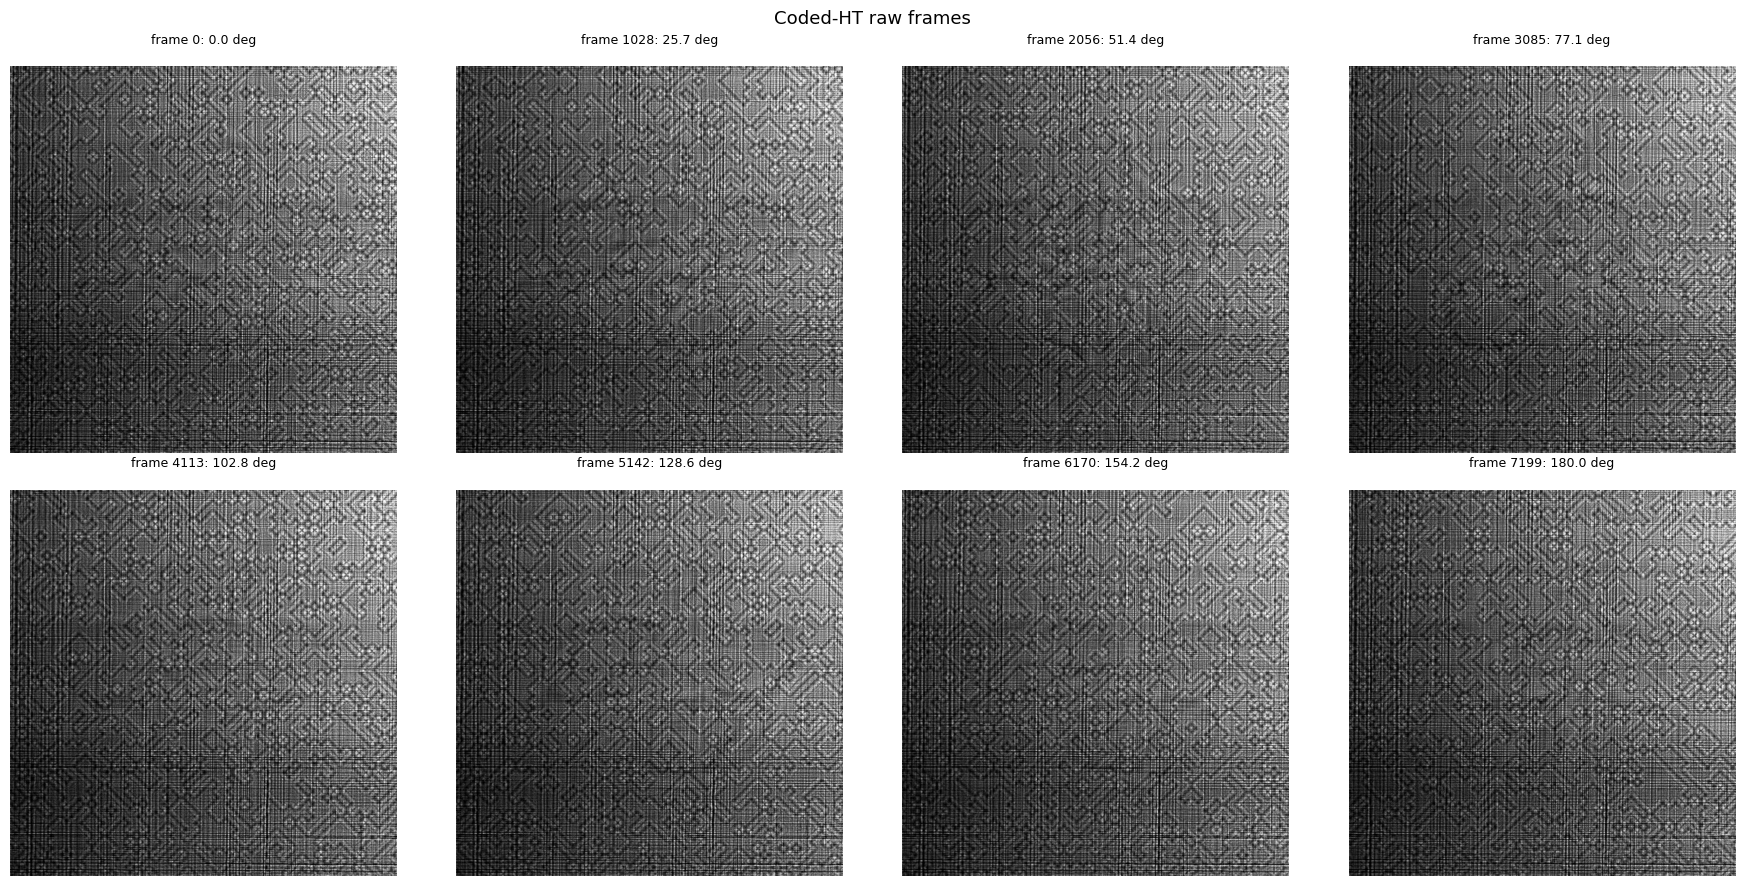

In [7]:
# Verify a few projection frames
sample_idx = np.linspace(0, ntheta-1, 8, dtype=int)
with h5py.File(fname_out, 'r') as f:
    frames  = f['/exchange/data'][sample_idx]
    theta_v = f['/exchange/theta'][:]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, frame, idx in zip(axes.flat, frames, sample_idx):
    ax.imshow(frame, cmap='gray', vmin=np.percentile(frame, 1), vmax=np.percentile(frame, 99))
    title = 'frame %d: %.1f deg\n' % (idx, theta_v[idx])
    ax.set_title(title, fontsize=9)
    ax.axis('off')
plt.suptitle('Coded-HT raw frames', fontsize=13)
plt.tight_layout(); plt.show()
